# Project Introduction
This project analyzes a customer-level dataset that includes demographic, financial, and behavioral variables such as age, gender, income category, credit limit, transaction amounts, credit utilization, and account activity. The dataset also contains a target variable, Attrition_Flag, which indicates whether a customer has remained with the company or closed their account. Using this data, the project investigates key questions: which factors such as spending behavior, credit usage, or customer characteristics influence customer churn, and how can these variables be used to predict which customers are at risk of leaving? By examining patterns across these features, the goal is to identify the primary drivers of attrition and support the development of a predictive model that enables targeted and effective customer retention strategies.

Link to Jupyter Notebook:

https://github.com/uic-ds-spring2026/class-project-space-monkeys/blob/main/churn-predictions.ipynb

## Any Changes?
We do not believe the scope of our project has changed since the last check-in.

## Importing data


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

%config InlineBackend.figure_formats = ['svg']
%matplotlib inline
sns.set_theme(context="notebook",
              style="ticks",
              palette="deep")
sns.set_style({"axes.grid":True})
# from google.colab import drive
# drive.mount('/content/drive')
# %cd "/content/drive/My Drive/CS418 - Spring 2026"

 Read the csv file using panda and using .info() to see what the data looks like

In [2]:
churn = pd.read_csv("./data/BankChurners.csv")
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

## Data Cleaning
Removing Irrelevant Columns: Dropped CLIENTNUM: This is a unique identifier for each row. Including it in a machine learning model can cause overfitting, as the model might try to learn patterns from random ID numbers. Dropped Naive_Bayes_Classifier.. (2 columns): These columns are predictions generated from a previous model. Keeping them would result model using the answers to predict the target variable, interfering our analysis.

In [3]:
churnData = churn.dropna().reset_index(drop=True)
churnData=churnData.drop("Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1",axis=1)
churnData=churnData.drop("Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2",axis=1)
churnData=churnData.drop("CLIENTNUM", axis=1)

Checking if there is any null values on any column


In [4]:
churnData.isnull().sum()

Attrition_Flag              0
Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Open_To_Buy             0
Total_Amt_Chng_Q4_Q1        0
Total_Trans_Amt             0
Total_Trans_Ct              0
Total_Ct_Chng_Q4_Q1         0
Avg_Utilization_Ratio       0
dtype: int64

Droping any duplicate rows which skews our distribution

In [5]:
churnData = churnData.drop_duplicates()

Converting all the object/string columns to category data types columns. This significantly improves memory usage and speeds up analytical processing in Pandas.

In [6]:
cat_cols = churnData.select_dtypes(include="object").columns
churnData[cat_cols] = churnData[cat_cols].astype("category")

## Summary statistics

Quick statistics of each columns in dataset including count, mean, median, max, min and quartiles

In [7]:
churnData.describe()

,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
count,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894
std,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691
min,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000
25%,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000
50%,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000
75%,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000
max,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000


Statistics of "Attrited Customer" aka Churned customer

In [8]:
churnData[churnData["Attrition_Flag"]=="Attrited Customer"].describe()


,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
count,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000
mean,46.659496,2.402581,36.178242,3.279656,2.693301,2.972342,8136.039459,672.822987,7463.216472,0.694277,3095.025814,44.933620,0.554386,0.162475
std,7.665652,1.275010,7.796548,1.577782,0.899623,1.090537,9095.334105,921.385582,9109.208129,0.214924,2308.227629,14.568429,0.226854,0.264458
min,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000
25%,41.000000,2.000000,32.000000,2.000000,2.000000,2.000000,2114.000000,0.000000,1587.000000,0.544500,1903.500000,37.000000,0.400000,0.000000
50%,47.000000,2.000000,36.000000,3.000000,3.000000,3.000000,4178.000000,0.000000,3488.000000,0.701000,2329.000000,43.000000,0.531000,0.000000
75%,52.000000,3.000000,40.000000,5.000000,3.000000,4.000000,9933.500000,1303.500000,9257.500000,0.856000,2772.000000,51.000000,0.692000,0.231000
max,68.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,1.492000,10583.000000,94.000000,2.500000,0.999000


Statistics of "Existing Customer"

In [9]:
churnData[churnData["Attrition_Flag"]!="Attrited Customer"].describe()

,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,46.262118,2.335412,35.880588,3.914588,2.273765,2.356353,8726.877518,1256.604118,7470.273400,0.772510,4654.655882,68.672588,0.742434,0.296412
std,8.081157,1.303229,8.021810,1.528949,1.016741,1.081436,9084.969807,757.745354,9087.671862,0.217783,3512.772635,22.919011,0.228054,0.272568
min,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,15.000000,0.256000,816.000000,11.000000,0.028000,0.000000
25%,41.000000,1.000000,31.000000,3.000000,1.000000,2.000000,2602.000000,800.000000,1184.500000,0.643000,2384.750000,54.000000,0.617000,0.055000
50%,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4643.500000,1364.000000,3469.500000,0.743000,4100.000000,71.000000,0.721000,0.211000
75%,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11252.750000,1807.000000,9978.250000,0.860000,4781.250000,82.000000,0.833000,0.529250
max,73.000000,5.000000,56.000000,6.000000,6.000000,5.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.994000


Distribution of men and women in the dataset, both overall and by churn status.

Overall, the dataset is relatively balanced in terms of gender; however, there are slightly more females than males, and females also have a higher churn rate compared to males.

In [10]:
print(churnData["Gender"].value_counts())
pd.crosstab(churnData['Gender'], churnData['Attrition_Flag'], normalize='index') * 100

Gender
F    5358
M    4769
Name: count, dtype: int64


Attrition_Flag,Attrited Customer,Existing Customer
Gender,,
F,17.357223,82.642777
M,14.615223,85.384777


Distribution of card category by churn status.

In [11]:
churnData.groupby("Attrition_Flag")["Card_Category"].value_counts()
pd.crosstab(
    churnData["Attrition_Flag"],
    churnData["Card_Category"],
    normalize="index"
) * 100

/var/folders/6c/cm1k07zs3w178xh7_91wj0f00000gn/T/ipykernel_96944/3359161378.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churnData.groupby("Attrition_Flag")["Card_Category"].value_counts()


Card_Category,Blue,Gold,Platinum,Silver
Attrition_Flag,,,,
Attrited Customer,93.362016,1.290719,0.307314,5.039951
Existing Customer,93.141176,1.117647,0.176471,5.564706


Distribution of maritial status among churned and existing customers.

In [12]:
churnData.groupby("Attrition_Flag")["Marital_Status"].value_counts()
pd.crosstab(
    churnData["Attrition_Flag"],
    churnData["Marital_Status"],
    normalize="index"
) * 100

/var/folders/6c/cm1k07zs3w178xh7_91wj0f00000gn/T/ipykernel_96944/367356646.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churnData.groupby("Attrition_Flag")["Marital_Status"].value_counts()


Marital_Status,Divorced,Married,Single,Unknown
Attrition_Flag,,,,
Attrited Customer,7.437001,43.577136,41.057160,7.928703
Existing Customer,7.376471,46.800000,38.529412,7.294118


Distribution of education levels among churned and existing customers.

In [13]:
churnData.groupby("Attrition_Flag")["Education_Level"].value_counts()
pd.crosstab(
    churnData["Attrition_Flag"],
    churnData["Education_Level"],
    normalize="index"
) * 100

/var/folders/6c/cm1k07zs3w178xh7_91wj0f00000gn/T/ipykernel_96944/2015769921.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churnData.groupby("Attrition_Flag")["Education_Level"].value_counts()


Education_Level,College,Doctorate,Graduate,High School,Post-Graduate,Uneducated,Unknown
Attrition_Flag,,,,,,,
Attrited Customer,9.465274,5.838967,29.932391,18.807621,5.654579,14.566687,15.734481
Existing Customer,10.105882,4.188235,31.070588,20.082353,4.988235,14.705882,14.858824


Distribution of Income Category among churned and existing customers.

In [14]:
churnData.groupby("Attrition_Flag")["Income_Category"].value_counts()
pd.crosstab(
    churnData["Attrition_Flag"],
    churnData["Income_Category"],
    normalize="index"
) * 100

/var/folders/6c/cm1k07zs3w178xh7_91wj0f00000gn/T/ipykernel_96944/174948776.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churnData.groupby("Attrition_Flag")["Income_Category"].value_counts()


Income_Category,$120K +,$40K - $60K,$60K - $80K,$80K - $120K,Less than $40K,Unknown
Attrition_Flag,,,,,,
Attrited Customer,7.744315,16.656423,11.616472,14.874001,37.615243,11.493546
Existing Customer,7.070588,17.870588,14.270588,15.211765,34.694118,10.882353


### What the data looks like
The dataset consists of 10,127 customer records and, after cleaning, 20 features/columns. The data consists:
Demographic Data: Customer Age, Gender, Education Level, Marital Status, Income Category, and Dependent Count.
Behavioral Data: Months on book, Credit Limit, Total Revolving Balance, Total Transaction Amount, Total Transaction Count, and Utilization Ratios. Target Variable: Attrition_Flag, which classifies customers as either an "Existing Customer" or an "Attrited Customer" (churned).

### Conclusions
Class Imbalance: By looking at the value counts, we can see that there are 8,500 Existing Customers and 1,627 Attrited Customers. This means our churn rate is roughly 16%. This is an interesting issue because it means our dataset is highly imbalanced.
Several categorical columns, such as Income_Category, Education_Level, and Marital_Status, contain many values labeled “Unknown.” These are not technically missing values, so they do not appear in a null-value check, but they still reduce the quality of the data because they limit how we can interpret patterns in those variables. For example, if a large share of customers have unknown income or education, it becomes harder to determine whether those demographic factors are truly related to churn.

/var/folders/6c/cm1k07zs3w178xh7_91wj0f00000gn/T/ipykernel_96944/3931815420.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition_Flag', y='Total_Trans_Ct', data=churnData, palette='Set2')


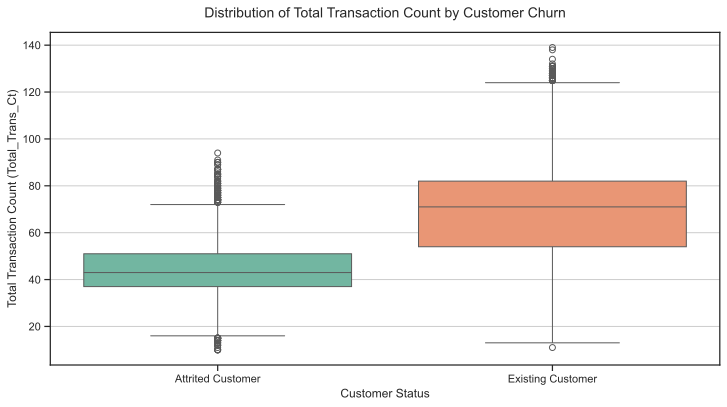

In [15]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Attrition_Flag', y='Total_Trans_Ct', data=churnData, palette='Set2')

plt.title('Distribution of Total Transaction Count by Customer Churn', fontsize=14, pad=15)
plt.xlabel('Customer Status', fontsize=12)
plt.ylabel('Total Transaction Count (Total_Trans_Ct)', fontsize=12)


plt.show()

## The Hypothesis
Customers who use their credit card less frequently are significantly more likely to churn than highly active customers. We thought this was interesting hypothesis to test since it focuses on customer behavior rather than only demographic traits. Behavioral variables often provide stronger signals of churn since they reflect how customers are actually interacting with the bank’s services. If a customer begins using their credit card less often, that may indicate reduced engagement, lower satisfaction, or a shift toward using another financial institution. This makes credit card activity a potentially valuable early warning sign for attrition.



## ML Analysis

We split the cleaned data into a training set (75%) and a test set (25%) with **stratified sampling** so the churn rate stays roughly the same in both splits. The target is **churn** (`Attrited Customer` = 1, `Existing Customer` = 0).

**Baseline:** always predict the majority class (no churn). Accuracy looks strong because most customers stay, but this rule **never** identifies churners, so recall for the churn class is zero.

**Models:** **logistic regression** uses scaled numeric columns and one-hot encoded categoricals (`class_weight='balanced'`). **random forest** uses the same encodings with trees that can capture non-linear patterns (`class_weight='balanced'`). We report **ROC–AUC**, **precision, recall, and F1** for the churn class, and **confusion matrices**—accuracy alone is misleading when the classes are imbalanced.

**Interpretation:** logistic coefficients and random forest importances relate back to exploratory analysis (for example, transaction activity and utilization).


Test-set metrics (positive class = churn):
                        model  accuracy  precision (churn)  recall (churn)  f1 (churn)  roc_auc
Baseline (majority: no churn)  0.839258           0.000000        0.000000    0.000000      NaN
          Logistic regression  0.853081           0.527646        0.820639    0.642308 0.918832
                Random forest  0.951817           0.884097        0.805897    0.843188 0.983614


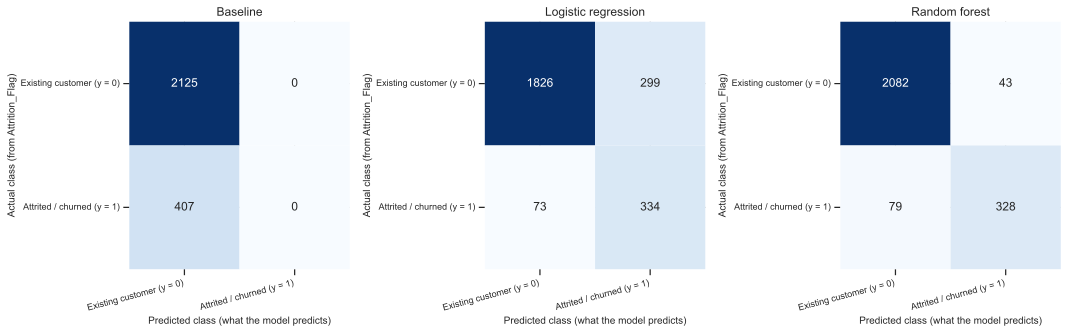

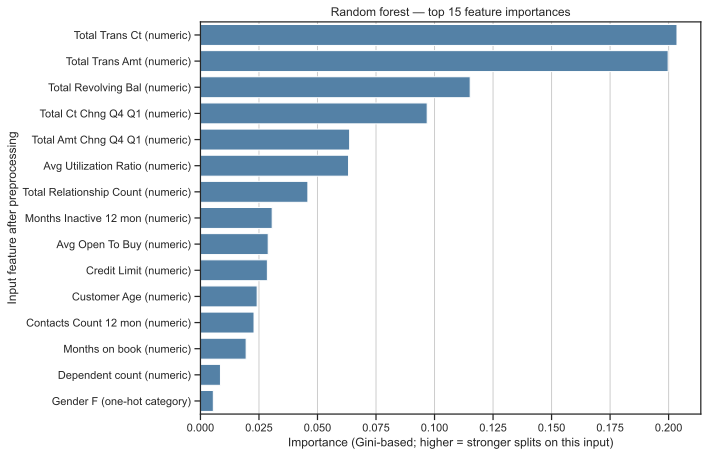

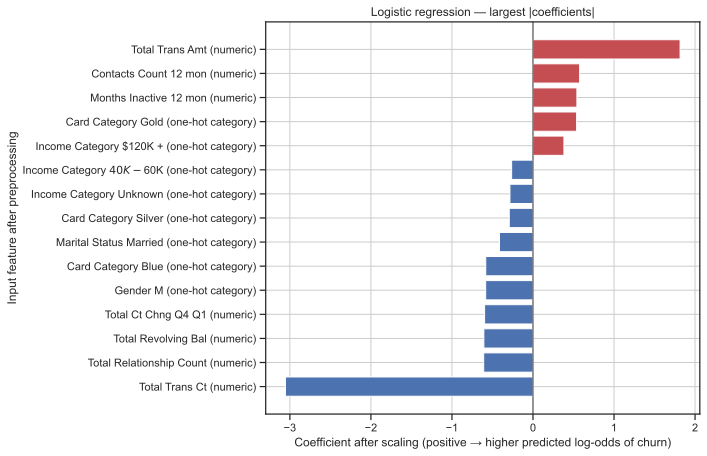

In [ ]:
# Target: 1 = churned (Attrited Customer)
y = (churnData["Attrition_Flag"] == "Attrited Customer").astype(int)
X = churnData.drop(columns=["Attrition_Flag"])

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Baseline: always predict majority class (here: no churn)
majority_label = int(y_train.mode()[0])
y_pred_baseline = np.full(shape=y_test.shape, fill_value=majority_label)


def eval_split(name, y_true, y_pred, y_score=None):
    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision (churn)": precision_score(y_true, y_pred, zero_division=0),
        "recall (churn)": recall_score(y_true, y_pred, zero_division=0),
        "f1 (churn)": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
    }
    return row


lr_preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

lr_pipe = Pipeline(
    [
        ("preprocess", lr_preprocess),
        (
            "clf",
            LogisticRegression(
                max_iter=5000,
                class_weight="balanced",
                solver="lbfgs",
            ),
        ),
    ]
)

lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)
y_score_lr = lr_pipe.predict_proba(X_test)[:, 1]

rf_preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

rf_pipe = Pipeline(
    [
        ("preprocess", rf_preprocess),
        (
            "clf",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=12,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

rf_pipe.fit(X_train, y_train)
y_pred_rf = rf_pipe.predict(X_test)
y_score_rf = rf_pipe.predict_proba(X_test)[:, 1]

metrics_df = pd.DataFrame(
    [
        eval_split("Baseline (majority: no churn)", y_test, y_pred_baseline),
        eval_split("Logistic regression", y_test, y_pred_lr, y_score_lr),
        eval_split("Random forest", y_test, y_pred_rf, y_score_rf),
    ]
)
print("Test-set metrics (positive class = churn):")
print(metrics_df.to_string(index=False))


def prettify_sklearn_feature(name: str) -> str:
    """Turn num__ / cat__ prefixes from ColumnTransformer into readable labels."""
    if name.startswith("num__"):
        return name[5:].replace("_", " ") + " (numeric)"
    if name.startswith("cat__"):
        return name[5:].replace("_", " ") + " (one-hot category)"
    return name.replace("_", " ")


# Match Attrition_Flag in the data: 0 = stayed, 1 = churned
CLASS_LABELS = [
    "Existing customer (y = 0)",
    "Attrited / churned (y = 1)",
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (title, y_pred) in zip(
    axes,
    [
        ("Baseline", y_pred_baseline),
        ("Logistic regression", y_pred_lr),
        ("Random forest", y_pred_rf),
    ],
):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_xlabel("Predicted class", fontsize=10)
    ax.set_ylabel("Actual class", fontsize=10)
    ax.set_xticklabels(CLASS_LABELS, rotation=15, ha="right", fontsize=9)
    ax.set_yticklabels(CLASS_LABELS, rotation=0, fontsize=9)
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Random forest: top feature importances (behavioral features often rank high)
feat_names = rf_pipe.named_steps["preprocess"].get_feature_names_out()
importances = rf_pipe.named_steps["clf"].feature_importances_
top_idx = np.argsort(importances)[-15:][::-1]
top_rf = pd.DataFrame({"feature": feat_names[top_idx], "importance": importances[top_idx]})
top_rf["feature_label"] = top_rf["feature"].map(prettify_sklearn_feature)

plt.figure(figsize=(10, 6.5))
sns.barplot(data=top_rf, x="importance", y="feature_label", color="steelblue")
plt.xlabel("Importance (higher = stronger splits on this input)")
plt.ylabel("Input feature after preprocessing")
plt.title("Random forest — top 15 feature importances")
plt.tight_layout()
plt.show()

# Logistic regression: largest |coefficients| (interpret with sign: positive → higher churn risk)
lr_names = lr_pipe.named_steps["preprocess"].get_feature_names_out()
lr_coef = lr_pipe.named_steps["clf"].coef_.ravel()
coef_df = pd.DataFrame({"feature": lr_names, "coef": lr_coef})
coef_df["abs_coef"] = coef_df["coef"].abs()
coef_df["feature_label"] = coef_df["feature"].map(prettify_sklearn_feature)
top_lr = coef_df.nlargest(15, "abs_coef")
plot_lr = top_lr.sort_values("coef")

plt.figure(figsize=(10, 6.5))
bar_colors = np.where(plot_lr["coef"].values >= 0, "#c44e52", "#4c72b0")
plt.barh(plot_lr["feature_label"], plot_lr["coef"], color=bar_colors)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel(
    "Coefficient after scaling"
)
plt.ylabel("Input feature after preprocessing")
plt.title("Logistic regression — largest |coefficients|")
plt.tight_layout()
plt.show()


## Reflection
- What is the hardest part of the project that you've encountered so far?
  - Addressing class imbalance has been particularly challenging, with only 16% of the customer churning. We had to employ class weighting and stratified sampling to attempt to address this.
- What are your initial insights?
  - The dataset we found was already cleaned, and this made pre-processing a straightforward process.
  - Total transaction count (Total_Trans_Ct) appears to be the most predictive feature.
  - Lower transactions, higher inactivity, higher customer service contact rates are a strong indicator of churn.
  - Demographic data (Gender, Income) do not play as big a role as we initially thought.
- Are there any concrete results you can show at this point? If not, why not?
  - Yes, so far, we have:
    - Summary stats and imbalance indications
    - A plot linking lower transaction activity to churn
    - ML Analysis - Majority baseline vs. Logistic Regression and Random Forest classifier
- Going forward, what are the current biggest problems you're facing?
  - The biggest problem we have is a lack of data, with 16% of customers churning. But we hope we can have more sweet spots for the threshold to proceed. Another huge problem is that we might have many null or unknown values that don't make it into the final data churn and proceed. It could cost a lot of valuable data.
- Do you think you are on track with your project? If not, what parts do you need to dedicate more time to?
  - Yes, we believe we are on track with overall progress. We finished all the data collection & cleaning. EDA & Statistical Analysis. We also performed ML Analysis against the baseline, and presented the results as visualizations shown above. The entire project scope has been mostly stable, as we see. However, we still need to focus more on identifying additional datasets for future forecasting and on summarizing the results we have found.  We would like to explore some potential business applications in the future.
- Given your initial exploration of the data, is it worth proceeding with your project, why? If not, how are you going to change your project and why do you think it’s better than your current results?
  - Yes, we believe it is worth proceeding with our project, we could see a lot of strong patterns and they could be easily explained in normal terms. In our EDA process, we found a clear pattern in the different behaviors of customers who stay and those who leave. It means we can, with forecasting, most of the time, tell the pattern of customers in those cases.

## Next Steps
- Research and attempt to implement another advanced model (Initial research suggest XGBoost, but we'd have to look into this more)
- Set up some concrete evaluation criteria for the performance of the models we use.
- Begin work on the final report & presentation.

## Gen AI Suggestions

We used **Claude** to obtain the necessary GenAI suggestion with the following prompt:

### Prompt Used:

We are working on a credit card churn prediction project using the Bank Churners dataset. Our current progress includes:
 The dataset we found was already cleaned, and this made pre-processing a straightforward process.
  - Total transaction count (Total_Trans_Ct) appears to be the most predictive feature.
  - Lower transactions, higher inactivity, higher customer service contact rates are a strong indicator of churn.
  - Demographic data (Gender, Income) do not play as big a role as we initially thought.

Please provide 5 high-level suggestions to improve our project.

---

### AI-Generated Suggestions:

Here are 5 high-level suggestions to improve your credit card churn prediction project:

**1. Enrich Your Feature Engineering**
Since Total_Trans_Ct is your strongest predictor, build derivative features around it — like transaction velocity (rate of change over time), recency-weighted transaction scores, or rolling averages. Behavioral trends often outperform raw totals, and capturing *how* usage is declining may be more predictive than the current count alone.

**2. Reframe Demographic Features Using Segmentation**
Rather than dropping Gender and Income outright, try using them to create customer segments, then train separate models per segment. A high-income customer churning may look very different from a low-income one, and demographic features may carry signal *within* a group even if they don't globally.

**3. Address Class Imbalance Explicitly**
Churn datasets are typically imbalanced (churners are the minority). If you haven't already, apply techniques like SMOTE, class-weighted loss functions, or threshold tuning on your classifier. Evaluating with AUC-ROC and F1 rather than accuracy will give you a more honest picture of model performance.

**4. Move Beyond a Single Model**
If you're using one model (e.g., logistic regression or a single decision tree), consider stacking or comparing multiple approaches — gradient boosting (XGBoost/LightGBM) tends to perform especially well on tabular churn data. Use SHAP values across models to validate that Total_Trans_Ct's importance is consistent and not an artifact of one algorithm.

**5. Build Toward a Business-Actionable Output**
Prediction alone isn't the end goal — reducing churn is. Map your model's probability scores to actionable tiers (e.g., high/medium/low risk), then estimate the cost-benefit of intervening on each tier. This bridges the gap between a data science result and a recommendation the business can actually act on.

The common thread across all five: your current findings are solid signals — these suggestions are about deepening and operationalizing them rather than starting over.

---